::: {.callout-note title="Versión resuelta"}
Incluye las soluciones de los ejercicios y los resultados de ejecutar cada celda. Para trabajar con el cuaderno, [descárgalo sin resultados](../../clabs/05/tema_05_svm.ipynb){download=""} o [ábrelo en Colab](https://colab.research.google.com/github/juanDmontoro/tap/blob/main/clabs/05/tema_05_svm.ipynb).
:::

**Técnicas Avanzadas de Predicción en Negocios · Cuaderno de práctica (nivel avanzado)**

Datos: Encuesta Cuatrienal de Estructura Salarial 2022 (INE), microdatos.

## Qué vamos a hacer

Una máquina de vectores de soporte (SVM) clasifica con una frontera y predice un valor numérico con una función, y las dos quedan fijadas por una parte de las observaciones, los **vectores de soporte**. En este cuaderno dibujamos esa frontera y esa función para ver qué hace el modelo, y después lo comparamos con los modelos que ya conocemos.

0. **Preparación.** Datos, respuestas, predictores, preprocesador y particiones.
1. **Margen y vectores de soporte.** Una SVM lineal para clasificar (SVC), su frontera, su margen y el papel de $C$.
2. **Núcleo y escalado.** El núcleo RBF curva la frontera, $\gamma$ fija cuánto y los predictores se escalan antes.
3. **Regresión con vectores de soporte.** La SVR, su tubo y el papel de $\varepsilon$.
4. **Ajuste de $C$ y $\gamma$.** Los dos hiperparámetros se eligen a la vez con validación cruzada.
5. **Comparación de modelos.** La SVM frente a la regresión lineal, el *random forest* y XGBoost: error, error típico y tiempo de ajuste.

Al final hay una **tarea opcional** con el núcleo polinómico.

- Hay cinco ejercicios y cinco «Para pensar» con la respuesta plegada. La tarea opcional añade un ejercicio.
- En cada ejercicio, la celda empieza vacía. El enunciado dice qué hacer y qué funciones usar, y casi siempre basta con adaptar una celda anterior.
- Las búsquedas de hiperparámetros prueban pocos valores, para que el cuaderno se ejecute en pocos minutos en cualquier ordenador.

## 0. Preparación

Usa el entorno `tap` del curso.

**Núcleos del procesador.**

- Un núcleo del procesador es una parte que realiza cálculos. Cuando hay varios, pueden trabajar a la vez.
- Consultamos con `os.cpu_count()` cuántas unidades de procesamiento reconoce el sistema y guardamos ese número menos uno en `N_NUCLEOS`, para dejar margen a otras tareas del ordenador.
- Más adelante usaremos esta variable como valor del argumento `n_jobs`, que controla cuántas tareas se ejecutan en paralelo, como los ajustes de la validación cruzada.
- Esta palabra tiene otro significado en este tema: el **núcleo** de una SVM (*kernel*), que aparece en el bloque 2, es una función que mide la semejanza entre dos observaciones.

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Máquinas de vectores de soporte: SVC clasifica y SVR predice un valor numérico.
from sklearn.svm import SVC, SVR

# Modelos de referencia.
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier

# Preprocesado de los predictores y de la respuesta.
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# División, validación cruzada, búsqueda de hiperparámetros y RMSE.
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV,
)
from sklearn.metrics import root_mean_squared_error

# Dibuja la frontera de un clasificador con dos predictores.
from sklearn.inspection import DecisionBoundaryDisplay

SEMILLA = 42

# Colores de las figuras, los mismos que en las diapositivas.
AZUL = "#447099"
TERRACOTA = "#E07A5F"

# Al repartir los ajustes de una SVM entre los núcleos, la biblioteca joblib puede mostrar un aviso
# que no afecta a los resultados. Lo ocultamos.
warnings.filterwarnings("ignore", message="A worker stopped")

# Núcleos para repartir el trabajo: todos los del ordenador menos uno (al menos uno).
N_NUCLEOS = max(1, os.cpu_count() - 1)
print("Núcleos para los cálculos en paralelo:", N_NUCLEOS)

Núcleos para los cálculos en paralelo: 11


### Datos y predictores

- Cargamos los microdatos de la EES 2022 y nos quedamos con los trabajadores que tienen un salario positivo y no superior al percentil 99.
- De ellos elegimos al azar 10 000, con la semilla 42.
- Usamos 16 predictores, 14 categóricos y 2 numéricos: la antigüedad en la empresa (`ANOANTI`, en años) y la jornada anual pactada (`JAP`, en horas).
- Dividimos los datos en entrenamiento (80 %) y test (20 %).

In [2]:
# Datos de la EES 2022 en la web del curso (separador: tabulación).
URL_DATOS = "https://juandmontoro.github.io/tap/data/EES_2022.tab"
df = pd.read_csv(URL_DATOS, sep="\t", low_memory=False)
df.columns = df.columns.str.replace('"', "").str.strip()

# Trabajadores con salario positivo y no superior al percentil 99.
tope = df["RETRINOIN"].quantile(0.99)
salario_admitido = (df["RETRINOIN"] > 0) & (df["RETRINOIN"] <= tope)
limpio = df[salario_admitido]

# 10 000 trabajadores elegidos al azar.
datos = limpio.sample(n=10000, random_state=SEMILLA).reset_index(drop=True)
print("Observaciones:", len(datos))

Observaciones: 10000


In [3]:
PRED_CATEGORICOS = [
    "SEXO", "ESTU", "ANOS2", "TIPOCON", "TIPOJOR", "CNO1", "CNACE",
    "CONTROL", "MERCADO", "REGULACION", "RESPONSA", "NUTS1", "TIPOPAIS", "ESTRATO2",
]
PRED_NUMERICOS = ["ANOANTI", "JAP"]

# X contiene los 16 predictores: categóricos como categorías y numéricos como decimales (float).
X = datos[PRED_CATEGORICOS + PRED_NUMERICOS].copy()
X[PRED_CATEGORICOS] = X[PRED_CATEGORICOS].astype("category")
X[PRED_NUMERICOS] = X[PRED_NUMERICOS].astype(float)

# y es el salario bruto anual, en euros.
y = datos["RETRINOIN"]

# División: 80 % entrenamiento y 20 % test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", len(X_train), "| test:", len(X_test))

Entrenamiento: 8000 | test: 2000


### Dos respuestas

Trabajamos con dos problemas sobre los mismos trabajadores.

- **Regresión.** La respuesta es el salario bruto anual (`RETRINOIN`), en euros. Medimos el error con el RMSE.
- **Clasificación.** La respuesta vale 1 (un **positivo**) si el salario supera el percentil 75 del entrenamiento, y 0 en otro caso. Así, un 25 % de los trabajadores tienen salario alto.
- El salario no es predictor, porque con él se definen las dos respuestas. El percentil 75 se calcula solo con el entrenamiento.

In [4]:
# Umbral del salario alto: percentil 75 del entrenamiento.
p75 = y_train.quantile(0.75)

# Respuesta binaria: 1 = salario alto, 0 = no. astype(int) convierte True/False en 1/0.
alto_train = (y_train > p75).astype(int)
alto_test = (y_test > p75).astype(int)

# La media de una variable 0/1 es la proporción de unos.
print("P75:", round(p75), "euros",
      "| proporción de positivos en el entrenamiento:", round(alto_train.mean(), 3))

P75: 34851 euros | proporción de positivos en el entrenamiento: 0.25


### Preprocesador y particiones

- El preprocesador aplica una transformación distinta a cada tipo de predictor.
- Los predictores numéricos se **estandarizan**: a cada uno se le resta su media y se divide entre su desviación típica. En el bloque 2 veremos por qué una SVM lo necesita.
- Cada predictor categórico se convierte en una columna por categoría, con un 1 si el trabajador la tiene y un 0 si no. Las categorías con menos del 1 % de los trabajadores se agrupan en una sola columna.
- El preprocesador va dentro de un `Pipeline` con el modelo, y así se ajusta solo con los datos de entrenamiento de cada partición.
- Las particiones `cv5` son las mismas en todo el cuaderno.

In [5]:
# Preprocesador: numéricas estandarizadas y una columna por categoría.
preprocesar = ColumnTransformer([
    ("numericas", StandardScaler(), PRED_NUMERICOS),
    ("categoricas",
     OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False),
     PRED_CATEGORICOS),
])

# Cinco particiones del entrenamiento, barajadas con la semilla.
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Bloque 1. Margen y vectores de soporte

## 1.1 Un problema para ver el margen

Para ver qué hace una SVM empezamos con un problema que se puede dibujar: dos predictores y dos clases que casi se separan con una recta.

- La respuesta de este bloque es el tipo de jornada: 1 si el trabajador tiene jornada a tiempo parcial (`TIPOJOR` = 2) y 0 si la tiene a tiempo completo.
- Los predictores son la antigüedad (`ANOANTI`) y la jornada anual pactada (`JAP`).
- Es un problema casi trivial, porque un trabajador a tiempo parcial tiene menos horas pactadas. Lo elegimos solo para dibujar la frontera. En el resto del cuaderno, el tipo de jornada vuelve a ser un predictor.
- Para que la figura se lea bien, tomamos 40 trabajadores del entrenamiento. Con `stratify=parcial`, `train_test_split` conserva en los 40 la proporción de trabajadores a tiempo parcial.

In [6]:
# Los dos predictores de las figuras.
DOS = ["ANOANTI", "JAP"]
X_dos = X_train[DOS]

# Respuesta de este bloque: 1 = jornada a tiempo parcial, 0 = tiempo completo.
parcial = (X_train["TIPOJOR"] == 2).astype(int)
print("Proporción de trabajadores a tiempo parcial:", round(parcial.mean(), 3))

# 40 trabajadores, con la misma proporción de tiempo parcial que el entrenamiento.
X_40, _, parcial_40, _ = train_test_split(X_dos, parcial, train_size=40,
                                          random_state=SEMILLA, stratify=parcial)

Proporción de trabajadores a tiempo parcial: 0.179


## 1.2 Frontera y vectores de soporte

Una SVM lineal para clasificar (`SVC` con `kernel="linear"`) calcula para cada observación una **puntuación**:

$$f(x) = \beta_0 + \beta_1 x_1 + \beta_2 x_2$$

- La **frontera** es la recta en la que $f(x) = 0$. A un lado, la SVC predice la clase 1 ($f(x) > 0$), y al otro, la clase 0.
- Muchas rectas separan las dos clases. La SVC elige la que deja la franja más ancha sin observaciones a los dos lados de la frontera. Esa franja es el **margen**, y sus bordes son las rectas $f(x) = 1$ y $f(x) = -1$.
- Las observaciones que quedan en el borde del margen, o dentro de él, son los **vectores de soporte**. Son las únicas que fijan la frontera.
- El hiperparámetro `C` es el coste de cada observación que queda dentro del margen o al otro lado de la frontera. Empezamos con un valor grande, `C=100`, que casi no admite ninguna.

En el código, `fit` ajusta el modelo y el atributo `support_` guarda la posición de los vectores de soporte dentro de los datos de ajuste. `decision_function` devuelve la puntuación $f(x)$.

In [7]:
# SVC lineal: los dos predictores estandarizados y C = 100.
svc_40 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=100)),
])
svc_40.fit(X_40, parcial_40)

# Posición de los vectores de soporte entre los 40 trabajadores.
posiciones = svc_40["modelo"].support_

# .iloc selecciona filas por posición: los vectores de soporte, con su clase y su puntuación f(x).
soporte_40 = X_40.iloc[posiciones].copy()
soporte_40["parcial"] = parcial_40.iloc[posiciones]
soporte_40["f(x)"] = svc_40.decision_function(X_40.iloc[posiciones]).round(2)
soporte_40

,ANOANTI,JAP,parcial,f(x)
1553,11.0,1519.0,0,-1.0
3321,10.0,1290.0,1,1.0


Ahora dibujamos el modelo. `DecisionBoundaryDisplay.from_estimator` calcula la puntuación en una rejilla de puntos y, con `levels=[-1, 0, 1]`, traza las tres rectas: la frontera y los dos bordes del margen.

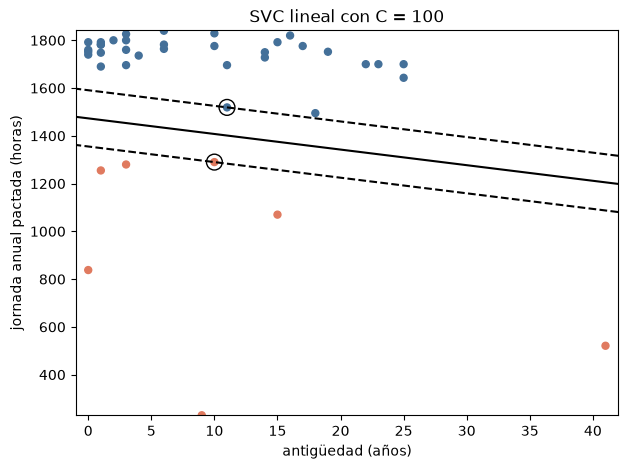

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))

# Frontera f(x) = 0 (línea continua) y bordes del margen f(x) = -1 y f(x) = 1 (líneas discontinuas).
DecisionBoundaryDisplay.from_estimator(
    svc_40,
    X_40,
    response_method="decision_function",
    plot_method="contour",
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"],
    colors="black",
    ax=ax,
)

# Los 40 trabajadores: en terracota la clase 1 (tiempo parcial) y en azul la clase 0.
# map sustituye cada 0 por el color azul y cada 1 por el terracota.
colores = parcial_40.map({0: AZUL, 1: TERRACOTA})
ax.scatter(X_40["ANOANTI"], X_40["JAP"], c=colores, s=25)

# Los vectores de soporte, rodeados con un círculo.
ax.scatter(soporte_40["ANOANTI"], soporte_40["JAP"], s=130, facecolors="none", edgecolors="black")

ax.set(xlabel="antigüedad (años)", ylabel="jornada anual pactada (horas)",
       title="SVC lineal con C = 100")
plt.show()

**Lectura de los resultados.**

- La línea continua es la frontera y las dos discontinuas, los bordes del margen. Entre ellas no hay ningún trabajador.
- La tabla tiene dos vectores de soporte, uno de cada clase: un trabajador a tiempo completo con 11 años de antigüedad y 1 519 horas, y uno a tiempo parcial con 10 años y 1 290 horas. Sus puntuaciones son −1 y 1, así que están justo en los bordes del margen.
- Los otros 38 trabajadores están más lejos de la frontera, y la SVC los clasifica bien a todos.
- La frontera es casi horizontal: la clase depende sobre todo de las horas pactadas.

---

Vamos a repetir esta figura con otros modelos, así que reunimos sus pasos en una función. Recibe un modelo ya ajustado, los datos, la respuesta, el panel donde se dibuja y un título.

In [9]:
def dibujar_frontera(modelo, X, respuesta, ax, titulo):
    # Frontera (línea continua) y bordes del margen (líneas discontinuas).
    DecisionBoundaryDisplay.from_estimator(
        modelo,
        X,
        response_method="decision_function",
        plot_method="contour",
        levels=[-1, 0, 1],
        linestyles=["--", "-", "--"],
        colors="black",
        ax=ax,
    )
    # Observaciones: en terracota la clase 1 y en azul la clase 0.
    colores = respuesta.map({0: AZUL, 1: TERRACOTA})
    ax.scatter(X["ANOANTI"], X["JAP"], c=colores, s=18)
    # Vectores de soporte, rodeados con un círculo.
    soporte = X.iloc[modelo["modelo"].support_]
    ax.scatter(soporte["ANOANTI"], soporte["JAP"], s=90, facecolors="none", edgecolors="black",
               linewidths=0.6)
    ax.set(xlabel="antigüedad (años)", ylabel="jornada anual pactada (horas)", title=titulo)

## 1.3 Margen blando y coste $C$

Con 40 trabajadores, una recta separa las dos clases. Con más datos, las clases se solapan y ninguna recta las separa sin errores.

- La SVC admite entonces observaciones dentro del margen o al otro lado de la frontera, y cada una tiene una pérdida que crece con la distancia a su borde del margen. Es el **margen blando**.
- La SVC busca a la vez un margen ancho y una suma de pérdidas pequeña. `C` es el coste de cada unidad de pérdida.
- Con un `C` grande, las pérdidas cuestan mucho y el margen se estrecha para tener pocas observaciones dentro. Con un `C` pequeño, el margen se ensancha y admite más.
- La anchura del margen es $2 / \sqrt{\beta_1^2 + \beta_2^2}$, medida en desviaciones típicas porque los predictores están estandarizados. Los coeficientes están en el atributo `coef_`, y `np.linalg.norm` calcula la raíz de la suma de sus cuadrados.

Tomamos 200 trabajadores y ajustamos la SVC con `C=100` y con `C=0.01`.

In [10]:
# 200 trabajadores, con la misma proporción de tiempo parcial que el entrenamiento.
X_200, _, parcial_200, _ = train_test_split(X_dos, parcial, train_size=200,
                                            random_state=SEMILLA, stratify=parcial)

# La misma SVC lineal con un coste grande y con uno pequeño.
svc_c100 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=100)),
])
svc_c100.fit(X_200, parcial_200)

svc_c001 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=0.01)),
])
svc_c001.fit(X_200, parcial_200)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['ANOANTI','JAP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


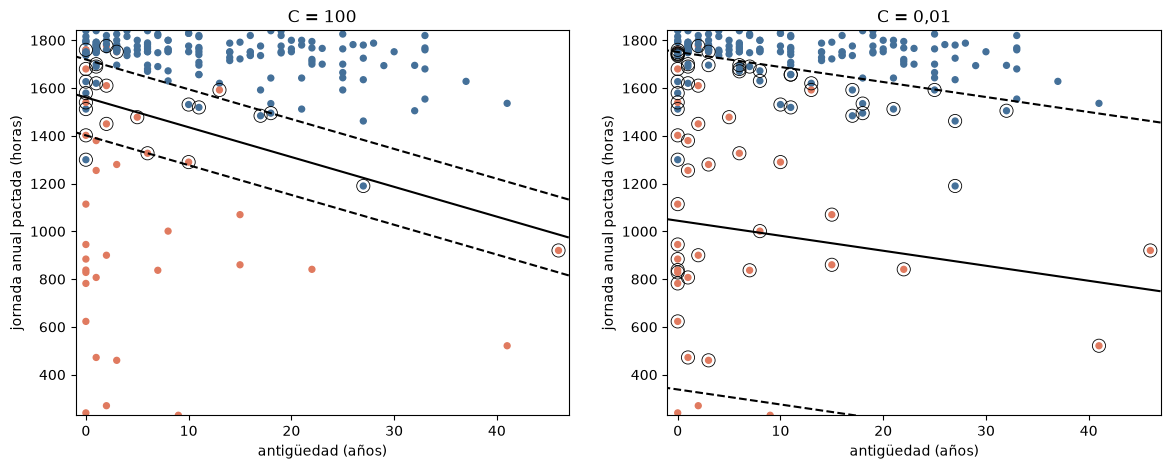

C = 100  | vectores de soporte: 25 | anchura del margen: 0.89
C = 0,01 | vectores de soporte: 66 | anchura del margen: 4.18


In [11]:
# Dos paneles, uno por valor de C.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
dibujar_frontera(svc_c100, X_200, parcial_200, ejes[0], "C = 100")
dibujar_frontera(svc_c001, X_200, parcial_200, ejes[1], "C = 0,01")
plt.show()

# Vectores de soporte y anchura del margen (en desviaciones típicas) de cada modelo.
print("C = 100  | vectores de soporte:", len(svc_c100["modelo"].support_),
      "| anchura del margen:", round(2 / np.linalg.norm(svc_c100["modelo"].coef_), 2))
print("C = 0,01 | vectores de soporte:", len(svc_c001["modelo"].support_),
      "| anchura del margen:", round(2 / np.linalg.norm(svc_c001["modelo"].coef_), 2))

**Lectura de los resultados.**

- Con 200 trabajadores hay solapamiento: algunos trabajadores a tiempo completo tienen menos horas pactadas que otros a tiempo parcial.
- Con $C$ = 100, el margen mide 0,89 desviaciones típicas y hay 25 vectores de soporte. Son los trabajadores que están en el margen o al otro lado de la frontera.
- Con $C$ = 0,01, el margen mide 4,18 desviaciones típicas y hay 66 vectores de soporte. El borde inferior del margen casi sale de la figura.
- Con el $C$ pequeño, la frontera baja hasta cerca de las 1 000 horas, y los trabajadores a tiempo parcial que quedan por encima de ella se clasifican como trabajadores a tiempo completo.

---

### Ejercicio 1. Otros valores de $C$

1. Ajusta la SVC lineal de 1.3 a los 200 trabajadores con `C=1` y con `C=0.1`. Llama a los modelos `svc_c1` y `svc_c01`.
2. Dibuja los dos modelos en una figura de dos paneles con `dibujar_frontera`.
3. Imprime el número de vectores de soporte y la anchura del margen de cada uno.
4. Con estos dos valores y los dos de 1.3, ¿qué relación hay entre `C`, la anchura del margen y el número de vectores de soporte? ¿Por qué?

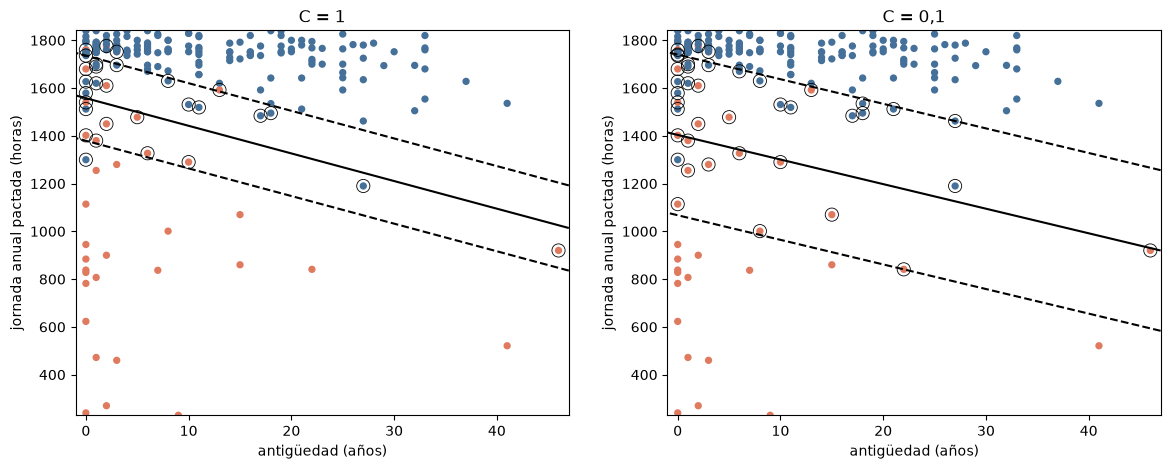

C = 1   | vectores de soporte: 29 | anchura del margen: 1.01
C = 0,1 | vectores de soporte: 40 | anchura del margen: 1.93


In [12]:
# Paso 1. SVC lineal con C = 1 y con C = 0,1.
svc_c1 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=1)),
])
svc_c1.fit(X_200, parcial_200)

svc_c01 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=0.1)),
])
svc_c01.fit(X_200, parcial_200)

# Paso 2. Un panel por valor de C.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
dibujar_frontera(svc_c1, X_200, parcial_200, ejes[0], "C = 1")
dibujar_frontera(svc_c01, X_200, parcial_200, ejes[1], "C = 0,1")
plt.show()

# Paso 3. Vectores de soporte y anchura del margen.
print("C = 1   | vectores de soporte:", len(svc_c1["modelo"].support_),
      "| anchura del margen:", round(2 / np.linalg.norm(svc_c1["modelo"].coef_), 2))
print("C = 0,1 | vectores de soporte:", len(svc_c01["modelo"].support_),
      "| anchura del margen:", round(2 / np.linalg.norm(svc_c01["modelo"].coef_), 2))

Paso 4. ¿Qué relación hay entre `C`, la anchura del margen y el número de vectores de soporte? ¿Por qué?

**Solución.**

- Los cuatro modelos, de mayor a menor $C$:

| $C$ | Vectores de soporte | Anchura del margen |
|---|---|---|
| 100 | 25 | 0,89 |
| 1 | 29 | 1,01 |
| 0,1 | 40 | 1,93 |
| 0,01 | 66 | 4,18 |

- Cuando $C$ baja, el margen se ensancha y el número de vectores de soporte sube.
- La razón está en lo que minimiza la SVC: busca un margen ancho y una suma de pérdidas pequeña, y $C$ es el coste de las pérdidas. Si $C$ es pequeño, tener observaciones dentro del margen cuesta poco, y la SVC prefiere un margen más ancho.
- Un margen más ancho contiene más observaciones, y todas las que están dentro del margen son vectores de soporte.
- Entre $C$ = 100 y $C$ = 1 el modelo casi no cambia (25 y 29 vectores de soporte). A partir de un valor, subir $C$ ya no estrecha el margen, porque las clases se solapan y siempre queda alguna observación al otro lado.

### Para pensar 1

En la figura de 1.2, un trabajador a tiempo completo con 1 800 horas pactadas pasa a tener 1 790. ¿Cambia la frontera? ¿Y si el que cambia es uno de los vectores de soporte?

<details><summary>Respuesta</summary>

- En el primer caso, la frontera no cambia de forma apreciable. Ese trabajador está lejos del margen, en el lado correcto, y su pérdida es cero antes y después del cambio. La solución la fijan los vectores de soporte.
- En rigor hay un cambio mínimo, porque los predictores se estandarizan con la media y la desviación típica de los 40 trabajadores, y esas dos cifras se mueven un poco.
- En el segundo caso, la frontera sí cambia. El margen se apoya en los vectores de soporte, y al mover uno se mueve el borde del margen.
- Una regresión logística se comporta de otra forma: todas las observaciones influyen en sus coeficientes, también las que están lejos de la frontera.

</details>

# Bloque 2. Núcleo y escalado

## 2.1 Un problema que una recta no resuelve

Volvemos a la respuesta de clasificación del cuaderno, el salario alto, con los mismos dos predictores.

- Para las figuras tomamos 300 trabajadores del entrenamiento, con la misma proporción de positivos.
- Ajustamos primero la SVC lineal del bloque 1, con `C=1`.

In [13]:
# 300 trabajadores, con la misma proporción de positivos que el entrenamiento.
X_300, _, alto_300, _ = train_test_split(X_dos, alto_train, train_size=300,
                                         random_state=SEMILLA, stratify=alto_train)

# SVC lineal con los dos predictores estandarizados.
svc_lineal = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="linear", C=1)),
])
svc_lineal.fit(X_300, alto_300)

# predict devuelve la clase predicha (0 o 1): su suma es el número de positivos predichos.
print("Positivos entre los 300 trabajadores:", alto_300.sum())
print("Positivos que predice la SVC lineal:", svc_lineal.predict(X_300).sum())

Positivos entre los 300 trabajadores: 75
Positivos que predice la SVC lineal: 0


**Lectura de los resultados.**

- De los 300 trabajadores, 75 tienen salario alto (el 25 %).
- La SVC lineal no predice ningún positivo. Clasifica a todos en la clase más frecuente, como un clasificador que no usa los predictores, y acierta el 75 %.
- Con estos dos predictores y `C=1`, la SVC lineal no separa a los trabajadores con salario alto.

---

## 2.2 Núcleo RBF

La SVC lineal no separa los positivos. Una salida conocida es añadir columnas (cuadrados, productos entre predictores) y ajustar un modelo lineal con ellas. La SVM consigue ese efecto sin construir las columnas, con un **núcleo** (*kernel*).

- Un núcleo es una función que mide la semejanza entre dos observaciones.
- El más usado es el **núcleo RBF**: $K(x, x') = \exp(-\gamma \, \lVert x - x' \rVert^2)$. Vale 1 si las dos observaciones coinciden y se acerca a 0 cuando la distancia entre ellas crece.
- Con un núcleo, la puntuación de una observación nueva es una suma de sus semejanzas con los vectores de soporte, cada una con un peso: $f(x) = \beta_0 + \sum_i v_i \, K(x, x_i)$.
- La observación nueva recibe la clase de los vectores de soporte a los que más se parece, y la frontera puede curvarse.
- $\gamma$ (`gamma`) fija el alcance de la semejanza. Con un $\gamma$ grande, la semejanza cae deprisa con la distancia y cada vector de soporte solo influye en su entorno más próximo.

Ajustamos una SVC con `kernel="rbf"` y `gamma=1` y la dibujamos junto a la lineal.

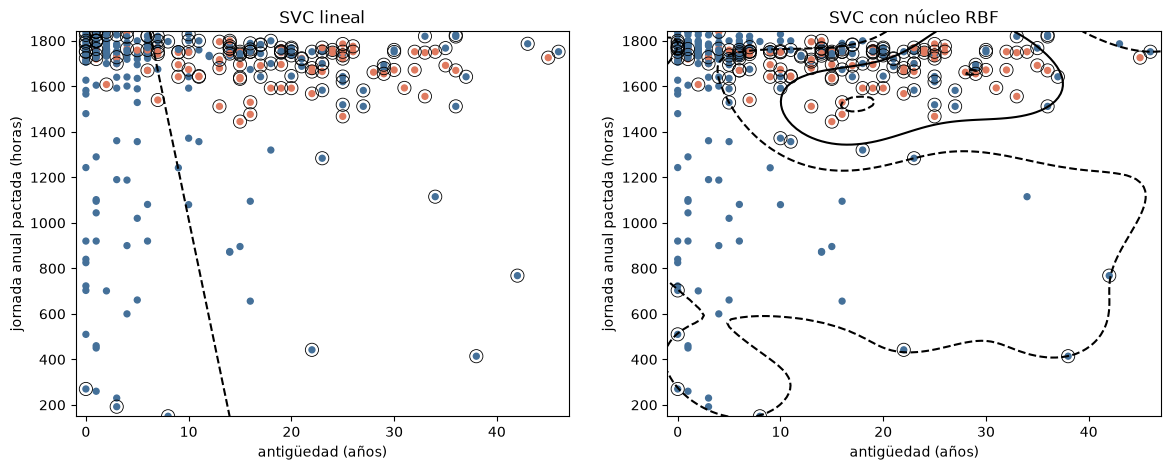

Positivos que predice la SVC con núcleo RBF: 58
Vectores de soporte | lineal: 156 | núcleo RBF: 160


In [14]:
# SVC con núcleo RBF: los mismos datos, C = 1 y gamma = 1.
svc_rbf = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="rbf", C=1, gamma=1)),
])
svc_rbf.fit(X_300, alto_300)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
dibujar_frontera(svc_lineal, X_300, alto_300, ejes[0], "SVC lineal")
dibujar_frontera(svc_rbf, X_300, alto_300, ejes[1], "SVC con núcleo RBF")
plt.show()

print("Positivos que predice la SVC con núcleo RBF:", svc_rbf.predict(X_300).sum())
print("Vectores de soporte | lineal:", len(svc_lineal["modelo"].support_),
      "| núcleo RBF:", len(svc_rbf["modelo"].support_))

**Lectura de los resultados.**

- En el panel de la SVC lineal no aparece la línea continua, y la línea discontinua no es un borde del margen. Lo comprobamos en la nota que sigue a esta lectura.
- En el panel del núcleo RBF, la frontera es una curva cerrada. Rodea la zona con más positivos: trabajadores con más de unos 10 años de antigüedad y una jornada cercana a la completa.
- La SVC con núcleo RBF predice 58 positivos.
- Con el núcleo RBF, 160 de los 300 trabajadores son vectores de soporte, más de la mitad, porque las clases se solapan mucho y muchos trabajadores quedan dentro del margen. Los 156 vectores de soporte de la SVC lineal se explican en la nota.

**Nota sobre el panel de la SVC lineal.**

- `DecisionBoundaryDisplay` dibuja las líneas en las que $f(x)$ vale −1, 0 y 1. Esas líneas solo existen si $f(x)$ cambia con la antigüedad o con la jornada.
- Extraemos los coeficientes de la SVC lineal, su puntuación $f(x)$ en los 300 trabajadores y la clase de sus vectores de soporte.

In [ ]:
# Coeficientes de la SVC lineal: f(x) = beta_0 + beta_1 x_1 + beta_2 x_2.
print("beta_0:", svc_lineal["modelo"].intercept_.round(3))
print("valor absoluto de beta_1 y beta_2:", np.abs(svc_lineal["modelo"].coef_).round(3))

# Puntuación f(x) de los 300 trabajadores.
f_lineal = svc_lineal.decision_function(X_300)
print("f(x) mínima:", f_lineal.min().round(3),
      "| f(x) máxima:", f_lineal.max().round(3))

# Vectores de soporte con salario alto.
posiciones_lineal = svc_lineal["modelo"].support_
print("Vectores de soporte con salario alto:", alto_300.iloc[posiciones_lineal].sum())

beta_0: [-1.]
valor absoluto de beta_1 y beta_2: [[0. 0.]]
f(x) mínima: -1.0 | f(x) máxima: -1.0
Vectores de soporte con salario alto: 75


**Lectura de los resultados.**

- $\beta_1$ y $\beta_2$ valen 0 y $\beta_0$ vale −1, así que $f(x) = -1$ para cualquier trabajador. La puntuación no depende de los predictores.
- Ningún punto del plano cumple $f(x) = 0$, así que la SVC lineal no tiene frontera, ni dentro ni fuera de la figura.
- Tampoco tiene bordes del margen, porque $f(x) = -1$ se cumple en todo el plano. Una igualdad que se cumple en todo el plano no se puede dibujar como una línea en $(x_1, x_2)$.
- El ajuste se detiene con una tolerancia y deja unos coeficientes minúsculos, que se redondean a 0. La línea discontinua es el lugar en el que esos restos cruzan el −1, y su posición no tiene ninguna lectura.
- Con $f(x) = -1$, todos los trabajadores reciben la clase 0, como vimos en 2.1.
- Los 156 vectores de soporte son los 75 trabajadores con salario alto, que la SVC clasifica mal, y 81 trabajadores de la clase 0. Todos tienen la misma puntuación, $f(x) = -1$, y no fijan ninguna frontera.

---

## 2.3 $\gamma$ y la curvatura de la frontera

Repetimos el ajuste con tres valores de $\gamma$: 0,1, 1 y 30. Como son tres modelos iguales salvo en ese valor, los ajustamos y dibujamos en un bucle.

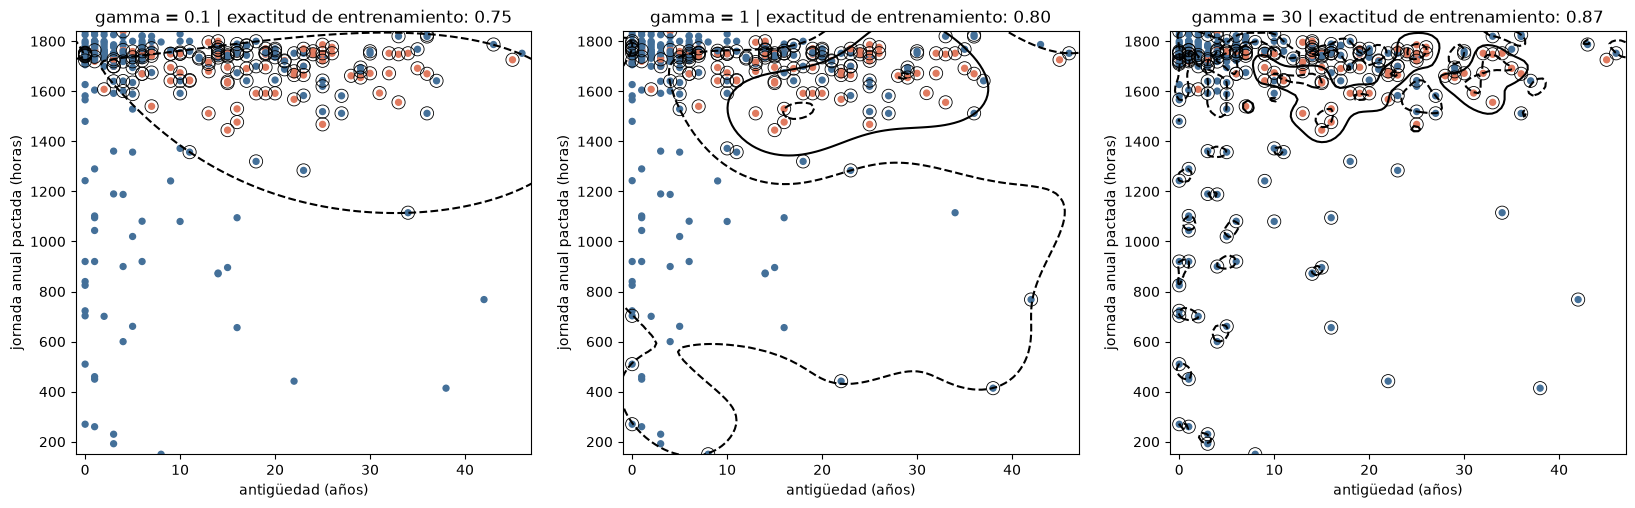

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5))

gamma_grid = [0.1, 1, 30]
# zip empareja cada panel con un valor de gamma.
for ax, gamma in zip(ejes, gamma_grid):
    # El mismo Pipeline de 2.2, con otro valor de gamma.
    modelo = Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", SVC(kernel="rbf", C=1, gamma=gamma)),
    ])
    modelo.fit(X_300, alto_300)

    # score devuelve la exactitud: la proporción de aciertos, aquí en los mismos 300 trabajadores.
    exactitud = modelo.score(X_300, alto_300)
    dibujar_frontera(modelo, X_300, alto_300, ax,
                     f"gamma = {gamma} | exactitud de entrenamiento: {exactitud:.2f}")
plt.show()

**Lectura de los resultados.**

- Con $\gamma$ = 0,1, la semejanza alcanza a trabajadores lejanos y la puntuación cambia despacio. No aparece la frontera: el modelo no predice ningún positivo y su exactitud de entrenamiento es 0,75.
- Con $\gamma$ = 1, la frontera rodea la zona con más positivos y la exactitud de entrenamiento sube a 0,80.
- Con $\gamma$ = 30, cada vector de soporte solo influye en su entorno más próximo. La frontera se rompe en islas alrededor de trabajadores sueltos y la exactitud de entrenamiento sube a 0,87.
- La exactitud de entrenamiento crece con $\gamma$. ¿Significa que el modelo con $\gamma$ = 30 predice mejor el salario alto de otros trabajadores?

---

### Ejercicio 2. ¿Qué $\gamma$ predice mejor?

La exactitud de entrenamiento no sirve para elegir $\gamma$. Además, con un 25 % de positivos la exactitud informa poco: un clasificador que no predice ningún positivo acierta el 75 %. Usamos la **precisión media** (*average precision*, AP).

- La precisión media mide si el modelo da puntuaciones más altas a los positivos que al resto. Resume la curva de precisión y sensibilidad que resulta al mover el umbral sobre la puntuación.
- Vale 1 si todos los positivos tienen más puntuación que todos los demás. Un clasificador que no usa los predictores tiene una precisión media igual a la proporción de positivos, aquí 0,25.
- Se calcula con la puntuación $f(x)$, sin necesidad de probabilidades. La SVC no da probabilidades.

1. Para cada $\gamma$ de 2.3 (0,1, 1 y 30), calcula la precisión media de entrenamiento y de validación cruzada con **todo el entrenamiento** (`X_dos` y `alto_train`). Usa `cross_validate` con `scoring="average_precision"`, `cv=cv5` y `return_train_score=True`: devuelve un diccionario con `train_score` y `test_score`, cinco valores cada uno.
2. Reúne las medias en una tabla con una fila por $\gamma$.
3. ¿Qué $\gamma$ elegirías? ¿Cuál sobreajusta, y cómo se ve en la tabla y en la figura de 2.3?

In [16]:
# Paso 1. Precisión media de entrenamiento y de validación cruzada con cada gamma.
filas = []
for gamma in [0.1, 1, 30]:
    modelo = Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", SVC(kernel="rbf", C=1, gamma=gamma)),
    ])
    resultado = cross_validate(modelo, X_dos, alto_train, scoring="average_precision",
                               cv=cv5, return_train_score=True, n_jobs=N_NUCLEOS)
    filas.append({
        "gamma": gamma,
        "precisión media de entrenamiento": resultado["train_score"].mean(),
        "precisión media de validación cruzada": resultado["test_score"].mean(),
    })

# Paso 2. Una fila por gamma.
tabla_gamma = pd.DataFrame(filas)
tabla_gamma.round(3)

,gamma,precisión media de entrenamiento,precisión media de validación cruzada
0,0.1,0.464,0.465
1,1.0,0.474,0.468
2,30.0,0.533,0.463


Paso 3. ¿Qué $\gamma$ elegirías? ¿Cuál sobreajusta, y cómo se ve en la tabla y en la figura de 2.3?

**Solución.**

- La tabla:

| $\gamma$ | Precisión media de entrenamiento | Precisión media de validación cruzada |
|---|---|---|
| 0,1 | 0,464 | 0,465 |
| 1 | 0,474 | 0,468 |
| 30 | 0,533 | 0,463 |

- La precisión media de validación cruzada es casi la misma con los tres valores (entre 0,463 y 0,468). Las diferencias son de 0,005 como mucho, y con ellas la validación cruzada deja los tres modelos empatados.
- La precisión media de entrenamiento sí sube con $\gamma$, de 0,464 a 0,533.
- El modelo con $\gamma$ = 30 sobreajusta: gana 0,07 en el entrenamiento y nada en la validación. En la figura de 2.3 se ve en las islas alrededor de trabajadores sueltos, que reproducen el entrenamiento y no se repiten con otros trabajadores.
- Con la misma precisión media de validación cruzada, elegimos un $\gamma$ pequeño, 0,1 o 1, que da la frontera más sencilla.
- Con dos predictores, la precisión media está lejos de 1. Supera el 0,25 de un clasificador que no usa los predictores, pero la antigüedad y la jornada no bastan para separar el salario alto.

## 2.4 Escalado de los predictores

El núcleo RBF mide distancias entre observaciones, y una distancia suma las diferencias de todos los predictores. Si un predictor tiene valores mucho mayores que otro, domina la suma.

- La jornada pactada se mide en horas al año y la antigüedad, en años.
- Comparamos la SVC con núcleo RBF con y sin el paso de escalado. En los dos modelos dejamos `gamma` en su valor por defecto, `gamma="scale"`.

**Qué significa `gamma="scale"`.** Con esta opción, scikit-learn calcula $\gamma$ con los datos que recibe la SVM en el ajuste:

$$\gamma = \frac{1}{p \cdot \text{Var}(X)}$$

- $p$ es el número de columnas que recibe la SVM y $\text{Var}(X)$, la varianza de todos los valores de esas columnas, tomados juntos.
- El núcleo RBF depende del producto de $\gamma$ por la distancia al cuadrado entre dos observaciones. Esa distancia crece con el número de columnas y con su varianza, y al dividir entre las dos, $\gamma$ se adapta a los datos.
- Con los dos predictores estandarizados, la varianza es 1 y $\gamma = 1 / (2 \cdot 1)$ = 0,5, la mitad del `gamma=1` de 2.2.
- Sin escalar, la varianza mezcla horas y años. Es un número muy grande, y $\gamma$ queda por debajo de una millonésima.
- Es un punto de partida razonable. El mejor valor se busca con validación cruzada, como haremos en el bloque 4.

ANOANTI     10.3
JAP        337.0
dtype: float64


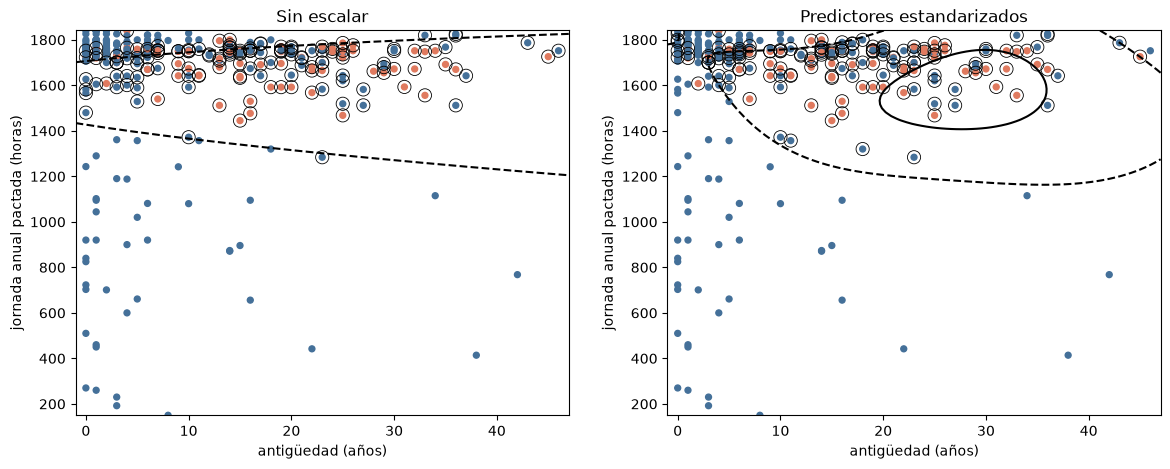

Positivos que predice | sin escalar: 0 | con los predictores estandarizados: 18


In [17]:
# Desviación típica de cada predictor en el entrenamiento.
print(X_dos.std().round(1))

# La misma SVC sin estandarizar y con los predictores estandarizados.
svc_sin_escalar = Pipeline([
    ("modelo", SVC(kernel="rbf", C=1)),
])
svc_sin_escalar.fit(X_300, alto_300)

svc_escalada = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="rbf", C=1)),
])
svc_escalada.fit(X_300, alto_300)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
dibujar_frontera(svc_sin_escalar, X_300, alto_300, ejes[0], "Sin escalar")
dibujar_frontera(svc_escalada, X_300, alto_300, ejes[1], "Predictores estandarizados")
plt.show()

print("Positivos que predice | sin escalar:", svc_sin_escalar.predict(X_300).sum(),
      "| con los predictores estandarizados:", svc_escalada.predict(X_300).sum())

In [ ]:
# Puntuación f(x) de la SVC sin escalar en los 300 trabajadores.
f_sin_escalar = svc_sin_escalar.decision_function(X_300)
print("Sin escalar | f(x) mínima:", f_sin_escalar.min().round(3),
      "| f(x) máxima:", f_sin_escalar.max().round(3))

Sin escalar | f(x) mínima: -1.014 | f(x) máxima: -0.998


**Lectura de los resultados.**

- La jornada pactada tiene una desviación típica de 337 horas y la antigüedad, de 10,3 años.
- Sin escalar, los bordes del margen son casi horizontales: la distancia entre dos trabajadores depende casi solo de sus horas pactadas, y la antigüedad apenas cuenta. El modelo no predice ningún positivo.
- **Aviso.** La celda anterior muestra que, sin escalar, $f(x)$ va de −1,014 a −0,998. Es negativa en todos los trabajadores, y por eso no hay frontera. Las dos líneas discontinuas son el nivel $f(x) = -1$ de una puntuación casi plana: diferencias de milésimas en $f(x)$ las desplazan, así que solo su dirección tiene lectura.
- Con los predictores estandarizados, la frontera es una curva cerrada que depende de las dos variables. El modelo predice 18 positivos.
- El escalado va dentro del `Pipeline`, para que la media y la desviación típica se calculen solo con los datos de ajuste.

---

### Para pensar 2

Si la jornada pactada se midiera en miles de horas (1,75 en lugar de 1 750), ¿cambiaría la frontera de la SVC sin escalar? ¿Y la de la SVC con los predictores estandarizados? ¿Le pasa lo mismo a un árbol de decisión?

<details><summary>Respuesta</summary>

- La frontera de la SVC sin escalar cambiaría. La información es la misma, pero el núcleo mide distancias y la distancia cambia con la unidad. En miles de horas, la jornada tendría una desviación típica de unas 0,3 unidades, y pasaría a dominar la antigüedad, con unas 10.
- La de la SVC con los predictores estandarizados no cambiaría. Al estandarizar, cada predictor queda con desviación típica 1, sea cual sea su unidad.
- A un árbol de decisión no le afecta. Corta cada predictor por separado, y al cambiar la unidad el corte se desplaza (de 1 600 a 1,6) sin que cambien las predicciones.
- Por eso se escala en los métodos que combinan los predictores en una distancia o en una penalización, como la SVM o la regresión con penalización.

</details>

# Bloque 3. Regresión con vectores de soporte

## 3.1 El tubo de la SVR

La SVM también predice un valor numérico. La versión de regresión se llama SVR.

- La SVR ajusta una función $f(x)$ y coloca a su alrededor un **tubo** de semianchura $\varepsilon$ (`epsilon`).
- Un residuo menor que $\varepsilon$ no cuenta: la observación está dentro del tubo y su pérdida es cero. Fuera del tubo, la pérdida es lo que el residuo excede de $\varepsilon$: $\max(0, \lvert y - f(x) \rvert - \varepsilon)$.
- Los **vectores de soporte** son las observaciones que quedan fuera del tubo o en su borde. Las de dentro no influyen en la función.
- `C` es, como en la SVC, el coste de cada unidad de pérdida.

**La respuesta se estandariza.** $\varepsilon$ se mide en las unidades de la respuesta, y un tubo de 0,5 euros no tendría sentido con salarios de decenas de miles de euros.

- `TransformedTargetRegressor` estandariza el salario antes de ajustar el modelo y devuelve las predicciones en euros.
- Así, `epsilon=0.5` es media desviación típica del salario.

Para dibujar el tubo usamos un solo predictor, la antigüedad, y 300 trabajadores a tiempo completo.

In [18]:
# Trabajadores a tiempo completo del entrenamiento: antigüedad y salario.
completa = X_train["TIPOJOR"] == 1
X_antiguedad = X_train.loc[completa, ["ANOANTI"]]
y_completa = y_train[completa]

# 300 de ellos para la figura.
X_1d, _, y_1d, _ = train_test_split(X_antiguedad, y_completa, train_size=300, random_state=SEMILLA)

# SVR lineal: predictor estandarizado dentro del Pipeline y respuesta estandarizada por fuera.
svr_1d = TransformedTargetRegressor(
    regressor=Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", SVR(kernel="linear", C=1, epsilon=0.5)),
    ]),
    transformer=StandardScaler(),
)
svr_1d.fit(X_1d, y_1d)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...l='linear'))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",StandardScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['ANOANTI']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,1
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...l='linear'))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,StandardScaler,StandardScaler()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalado', ...), ('modelo', ...)]"


Tras el ajuste, `regressor_` es el `Pipeline` ajustado y `transformer_`, el escalado de la respuesta. De ellos leemos los vectores de soporte y la desviación típica del salario, que convierte $\varepsilon$ en euros.

Desviación típica del salario: 18089 euros | semianchura del tubo: 9044 euros
Vectores de soporte: 153 de 300


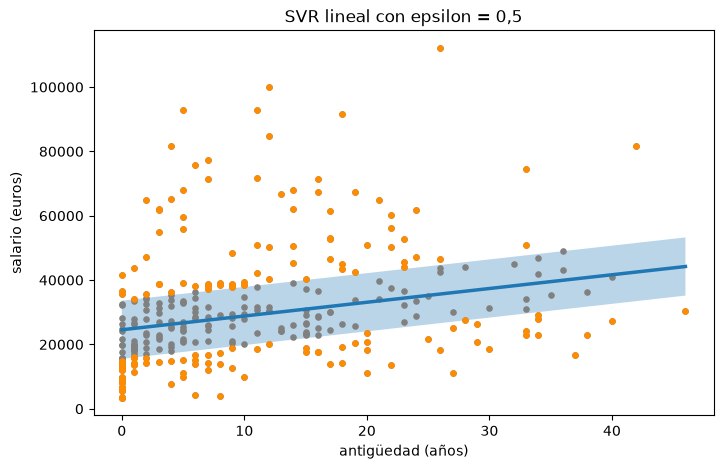

In [19]:
# Semianchura del tubo en euros: epsilon por la desviación típica del salario de los 300 trabajadores.
desviacion_salario = svr_1d.transformer_.scale_[0]
semianchura = 0.5 * desviacion_salario
print("Desviación típica del salario:", round(desviacion_salario), "euros",
      "| semianchura del tubo:", round(semianchura), "euros")

# Predicción para cada antigüedad entre 0 y el máximo.
rejilla = pd.DataFrame({"ANOANTI": np.linspace(0, X_1d["ANOANTI"].max(), 200)})
prediccion = svr_1d.predict(rejilla)

# Posición de los vectores de soporte entre los 300 trabajadores.
posiciones = svr_1d.regressor_["modelo"].support_
print("Vectores de soporte:", len(posiciones), "de", len(X_1d))

fig, ax = plt.subplots(figsize=(8, 5))

# El tubo y la función.
ax.fill_between(rejilla["ANOANTI"], prediccion - semianchura, prediccion + semianchura, alpha=0.3)
ax.plot(rejilla["ANOANTI"], prediccion, linewidth=2.5)

# Todos los trabajadores en gris y, encima, los vectores de soporte en naranja.
ax.scatter(X_1d["ANOANTI"], y_1d, s=14, color="gray")
ax.scatter(X_1d["ANOANTI"].iloc[posiciones], y_1d.iloc[posiciones], s=14, color="darkorange")

ax.set(xlabel="antigüedad (años)", ylabel="salario (euros)", title="SVR lineal con epsilon = 0,5")
plt.show()

**Lectura de los resultados.**

- La desviación típica del salario de los 300 trabajadores es de 18 089 euros. Con $\varepsilon$ = 0,5, el tubo llega 9 044 euros por encima y por debajo de la recta.
- La recta sube con la antigüedad, de unos 25 000 euros sin antigüedad a unos 44 000 con 45 años.
- Los puntos grises están dentro del tubo y no influyen en la recta. Los naranjas son los vectores de soporte: 153 de 300, los trabajadores que quedan fuera del tubo o en su borde.
- Los vectores de soporte de encima del tubo están más lejos de él que los de debajo: son los salarios altos.

---

Como en el bloque 1, reunimos los pasos de la figura en una función. Recibe una SVR ya ajustada y lee de ella el valor de $\varepsilon$.

In [20]:
def dibujar_tubo(modelo, X, y, ax, titulo):
    # Semianchura del tubo en euros.
    epsilon = modelo.regressor_["modelo"].epsilon
    semianchura = epsilon * modelo.transformer_.scale_[0]
    # Predicción para cada antigüedad.
    rejilla = pd.DataFrame({"ANOANTI": np.linspace(0, X["ANOANTI"].max(), 200)})
    prediccion = modelo.predict(rejilla)
    # El tubo y la función.
    ax.fill_between(rejilla["ANOANTI"],
                    prediccion - semianchura,
                    prediccion + semianchura,
                    alpha=0.3)
    ax.plot(rejilla["ANOANTI"], prediccion, linewidth=2.5)
    # Observaciones en gris y vectores de soporte en naranja.
    posiciones = modelo.regressor_["modelo"].support_
    ax.scatter(X["ANOANTI"], y, s=14, color="gray")
    ax.scatter(X["ANOANTI"].iloc[posiciones], y.iloc[posiciones], s=14, color="darkorange")
    ax.set(xlabel="antigüedad (años)", ylabel="salario (euros)",
           title=f"{titulo} | vectores de soporte: {len(posiciones)}")

## 3.2 SVR con núcleo RBF

Con el núcleo RBF, la función de la SVR deja de ser una recta. $\gamma$ hace el mismo papel que en la SVC: con un valor grande, cada vector de soporte solo influye en las antigüedades más próximas a la suya.

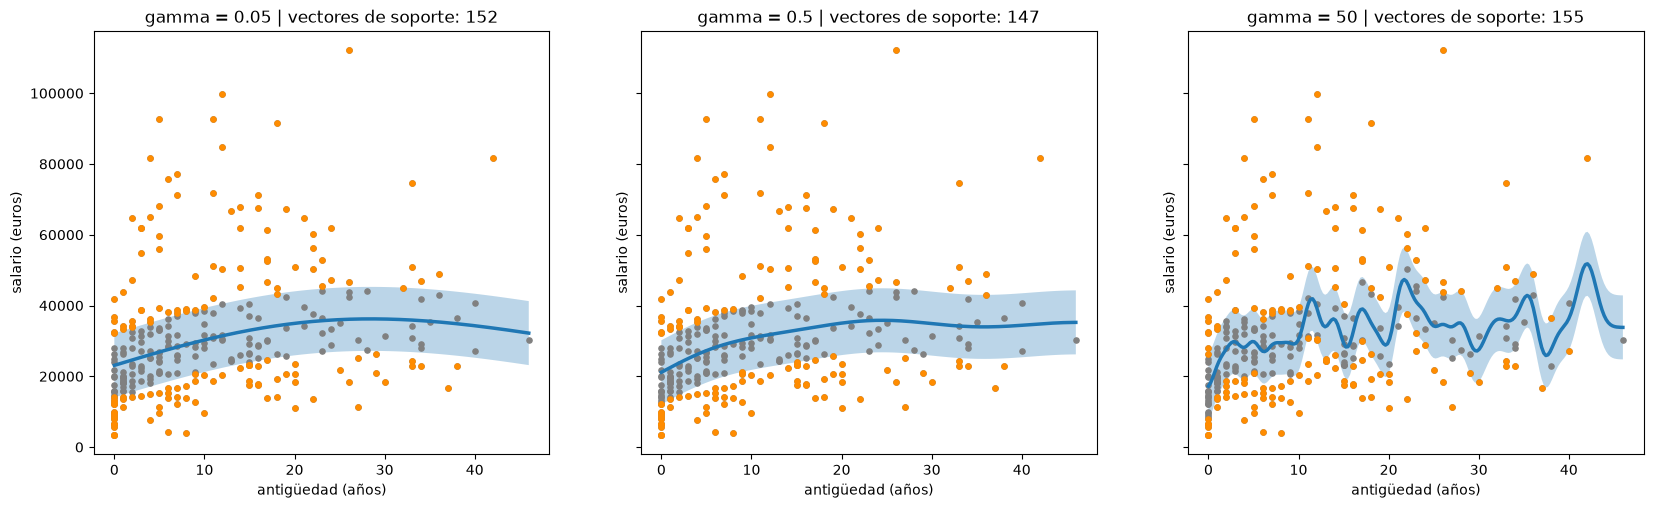

In [21]:
fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)

gamma_grid = [0.05, 0.5, 50]
for ax, gamma in zip(ejes, gamma_grid):
    # La SVR de 3.1 con núcleo RBF y otro valor de gamma.
    modelo = TransformedTargetRegressor(
        regressor=Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", SVR(kernel="rbf", C=1, epsilon=0.5, gamma=gamma)),
        ]),
        transformer=StandardScaler(),
    )
    modelo.fit(X_1d, y_1d)
    dibujar_tubo(modelo, X_1d, y_1d, ax, f"gamma = {gamma}")
plt.show()

**Lectura de los resultados.**

- Con $\gamma$ = 0,05, la función es una curva suave: sube en los primeros años de antigüedad y se aplana después.
- Con $\gamma$ = 0,5, la subida de los primeros 15 años es más rápida y después la función queda cerca de los 35 000 euros.
- Con $\gamma$ = 50, la función sube y baja para acercarse a trabajadores sueltos. Con otros 300 trabajadores, esos picos estarían en otro sitio.
- El número de vectores de soporte es parecido en los tres paneles (152, 147 y 155), aunque la función cambia mucho. ¿De qué depende entonces?

---

### Ejercicio 3. La anchura del tubo

1. Ajusta la SVR lineal de 3.1 con `epsilon` igual a 0,1, 0,5 y 1.
2. Dibuja los tres modelos en una figura de tres paneles con `dibujar_tubo`, que escribe en el título el número de vectores de soporte.
3. ¿Cómo cambia el número de vectores de soporte con $\varepsilon$? ¿Por qué? ¿Qué trabajadores fijan la recta con `epsilon=1`?

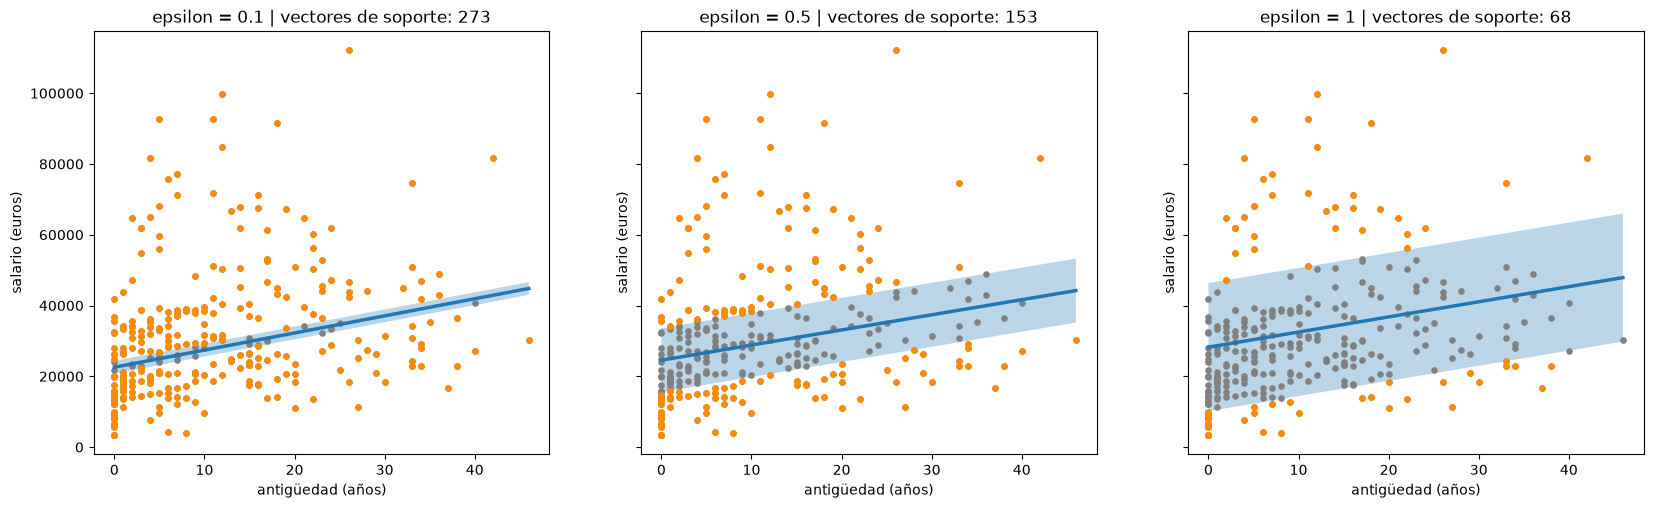

In [22]:
# Pasos 1 y 2. SVR lineal con tres valores de epsilon, un panel por valor.
fig, ejes = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)

epsilon_grid = [0.1, 0.5, 1]
for ax, epsilon in zip(ejes, epsilon_grid):
    modelo = TransformedTargetRegressor(
        regressor=Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", SVR(kernel="linear", C=1, epsilon=epsilon)),
        ]),
        transformer=StandardScaler(),
    )
    modelo.fit(X_1d, y_1d)
    dibujar_tubo(modelo, X_1d, y_1d, ax, f"epsilon = {epsilon}")
plt.show()

Paso 3. ¿Cómo cambia el número de vectores de soporte con $\varepsilon$? ¿Por qué? ¿Qué trabajadores fijan la recta con `epsilon=1`?

**Solución.**

- Hay 273 vectores de soporte con $\varepsilon$ = 0,1, 153 con $\varepsilon$ = 0,5 y 68 con $\varepsilon$ = 1.
- Cuanto más ancho es el tubo, más trabajadores quedan dentro, con pérdida cero. Solo los de fuera o del borde son vectores de soporte.
- Con $\varepsilon$ = 0,1, el tubo mide unos 1 800 euros a cada lado y casi todos los trabajadores quedan fuera: la recta depende de casi todos, como en una regresión lineal.
- Con $\varepsilon$ = 1, el tubo llega una desviación típica (unos 18 000 euros) a cada lado. La recta la fijan 68 trabajadores: los que tienen un salario a más de una desviación típica de la recta, por encima o por debajo. Los otros 232 quedan dentro del tubo y no influyen.
- $\varepsilon$ expresa cuánto error se tolera sin coste. Un valor muy grande deja la función en manos de pocas observaciones, y uno muy pequeño hace que todas cuenten.

## 3.3 Respuesta en euros y respuesta estandarizada

Pasamos al modelo completo, con los 16 predictores y los 8 000 trabajadores del entrenamiento. Comparamos dos versiones de la SVR con núcleo RBF y los valores por defecto (`C=1`, `epsilon=0.1` y `gamma="scale"`, que se calcula con la fórmula de 2.4).

- La primera recibe el salario en euros.
- La segunda recibe el salario estandarizado, con `TransformedTargetRegressor`.

`cross_val_score` ajusta el modelo cinco veces, una por partición de `cv5`, y con `scoring="neg_root_mean_squared_error"` devuelve los cinco RMSE de validación con el signo cambiado.

In [23]:
# SVR con la respuesta en euros.
svr_euros = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", SVR(kernel="rbf")),
])

puntuaciones_euros = cross_val_score(svr_euros, X_train, y_train,
                                     scoring="neg_root_mean_squared_error",
                                     cv=cv5, n_jobs=N_NUCLEOS)

# scikit-learn devuelve el RMSE con el signo cambiado: lo pasamos a positivo.
print("SVR con la respuesta en euros     | RMSE de validación cruzada:",
      round(-puntuaciones_euros.mean()), "euros")

SVR con la respuesta en euros     | RMSE de validación cruzada: 18691 euros


In [24]:
# La misma SVR con la respuesta estandarizada.
svr_estandarizada = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocesado", preprocesar),
        ("modelo", SVR(kernel="rbf")),
    ]),
    transformer=StandardScaler(),
)

puntuaciones_estandarizada = cross_val_score(svr_estandarizada, X_train, y_train,
                                             scoring="neg_root_mean_squared_error",
                                             cv=cv5, n_jobs=N_NUCLEOS)

print("SVR con la respuesta estandarizada | RMSE de validación cruzada:",
      round(-puntuaciones_estandarizada.mean()), "euros",
      "| error típico:", round(puntuaciones_estandarizada.std() / np.sqrt(5)))
print("Desviación típica del salario en el entrenamiento:", round(y_train.std(ddof=0)), "euros")

SVR con la respuesta estandarizada | RMSE de validación cruzada: 11227 euros | error típico: 192
Desviación típica del salario en el entrenamiento: 18304 euros


**Lectura de los resultados.**

- Con la respuesta en euros, el RMSE de validación cruzada es de 18 691 euros. Es mayor que la desviación típica del salario (18 304 euros), que es el RMSE de predecir a todos los trabajadores el salario medio.
- Con la respuesta estandarizada, el RMSE baja a 11 227 euros, con un error típico de 192 euros.
- El modelo es el mismo. Cambia la unidad de la respuesta, y con ella el significado de `C` y de `epsilon`.
- Con el salario en euros, un tubo de 0,1 euros no deja a nadie dentro. Además, el peso de cada vector de soporte en la predicción está limitado por `C`: con `C=1`, cada uno mueve la predicción un euro como mucho, y la función queda casi plana.
- Con el salario estandarizado, los valores por defecto están en la escala de la respuesta.

**Regla práctica.** En una SVR se estandarizan los predictores y la respuesta.

---

### Para pensar 3

Un trabajador del entrenamiento tiene un salario 60 000 euros mayor que el que predice el modelo. ¿Influye más en una regresión lineal por mínimos cuadrados o en una SVR? ¿Y un trabajador con un residuo de 500 euros?

<details><summary>Respuesta</summary>

- El trabajador con el residuo de 60 000 euros influye más en la regresión lineal. Mínimos cuadrados eleva el residuo al cuadrado, y un residuo diez veces mayor pesa cien veces más.
- En la SVR, la pérdida fuera del tubo crece en proporción al residuo. Un residuo diez veces mayor pesa unas diez veces más, y cada euro de más añade lo mismo. Por eso la SVR depende menos de unos pocos salarios muy altos.
- El trabajador con el residuo de 500 euros influye en la regresión lineal, aunque poco. En la SVR queda dentro del tubo, su pérdida es cero y no influye en la función: no es un vector de soporte.

</details>

# Bloque 4. Ajuste de $C$ y $\gamma$

## 4.1 Búsqueda para la SVR

Una SVM con núcleo RBF tiene dos hiperparámetros que se eligen con validación cruzada: `C` y `gamma`. Los buscamos a la vez con `GridSearchCV`.

- La malla tiene cuatro valores de `C` y cuatro de `gamma`, separados por un factor 10. Son 16 combinaciones y, como cada una se ajusta en las cinco particiones, 80 ajustes.
- `epsilon` se queda en 0,1, una décima de la desviación típica del salario.
- En la malla, el nombre de cada hiperparámetro lleva delante el camino hasta él, con dos guiones bajos entre los pasos: `regressor` (el `Pipeline` dentro de `TransformedTargetRegressor`), `modelo` (el paso de la SVR) y el hiperparámetro.
- `GridSearchCV` prueba las combinaciones en copias del modelo y guarda los resultados en `cv_results_`.

In [25]:
# SVR con núcleo RBF y la respuesta estandarizada.
svr = TransformedTargetRegressor(
    regressor=Pipeline([
        ("preprocesado", preprocesar),
        ("modelo", SVR(kernel="rbf", epsilon=0.1)),
    ]),
    transformer=StandardScaler(),
)

# Malla: cuatro valores de C y cuatro de gamma.
malla_svr = {
    "regressor__modelo__C": [0.1, 1, 10, 100],
    "regressor__modelo__gamma": [0.001, 0.01, 0.1, 1],
}

busqueda_svr = GridSearchCV(
    estimator=svr,
    param_grid=malla_svr,
    scoring="neg_root_mean_squared_error",
    cv=cv5,
    n_jobs=N_NUCLEOS,
)
busqueda_svr.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",TransformedTa...ndardScaler())
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'regressor__modelo__C': [0.1, 1, ...], 'regressor__modelo__gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",11
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable add

Pasamos los resultados a una tabla con una fila por valor de `C` y una columna por valor de `gamma`, y la dibujamos como un mapa de calor. `pivot` reorganiza la tabla y `sns.heatmap` la dibuja con un color por casilla, más oscuro cuanto menor es el RMSE.

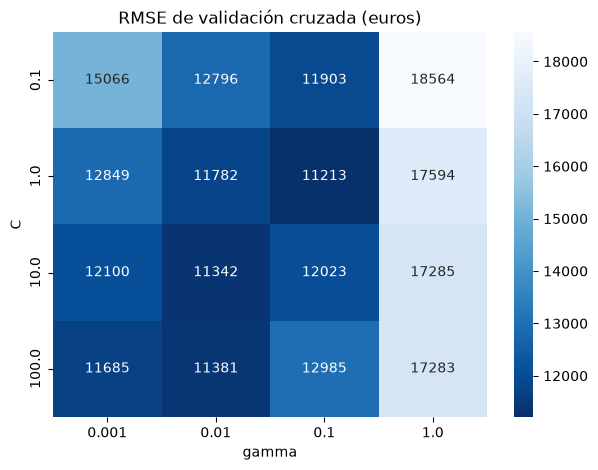

In [26]:
# Resultados de la búsqueda: una fila por combinación.
resultados_svr = pd.DataFrame(busqueda_svr.cv_results_)

# RMSE de validación cruzada, con el signo en positivo, y su error típico.
resultados_svr["rmse"] = -resultados_svr["mean_test_score"]
resultados_svr["error_tipico"] = resultados_svr["std_test_score"] / np.sqrt(5)

# Una fila por C y una columna por gamma.
mapa_svr = resultados_svr.pivot(index="param_regressor__modelo__C",
                                columns="param_regressor__modelo__gamma",
                                values="rmse")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(mapa_svr, annot=True, fmt=".0f", cmap="Blues_r", ax=ax)
ax.set(xlabel="gamma", ylabel="C", title="RMSE de validación cruzada (euros)")
plt.show()

In [27]:
# Combinación con el menor RMSE de validación cruzada, con su RMSE y su error típico.
print("Combinación elegida:", busqueda_svr.best_params_)
fila_elegida = resultados_svr.loc[busqueda_svr.best_index_]
print("RMSE de validación cruzada:", round(fila_elegida["rmse"]), "euros",
      "| error típico:", round(fila_elegida["error_tipico"]))

# Desde aquí, svr es el modelo elegido, ajustado con todo el entrenamiento.
svr = busqueda_svr.best_estimator_

Combinación elegida: {'regressor__modelo__C': 1, 'regressor__modelo__gamma': 0.1}
RMSE de validación cruzada: 11213 euros | error típico: 181


**Lectura de los resultados.**

- El RMSE de validación cruzada menor es 11 213 euros, con $C$ = 1 y $\gamma$ = 0,1. Su error típico es de 181 euros.
- La columna de $\gamma$ = 1 es la peor, con más de 17 000 euros en todas sus casillas. Con ese $\gamma$, cada vector de soporte solo influye en trabajadores casi idénticos a él, y ningún $C$ lo corrige.
- La esquina de $C$ = 0,1 y $\gamma$ = 0,001 también es mala (15 066 euros): la función es demasiado plana.
- Otras casillas quedan a menos de un error típico de la elegida, como $C$ = 10 con $\gamma$ = 0,01 (11 342 euros) y $C$ = 100 con $\gamma$ = 0,01 (11 381). La validación cruzada no distingue esas combinaciones.
- Con dos hiperparámetros buscados a la vez no hay un orden claro de sencillez entre las combinaciones, y elegimos la de menor RMSE.

---

### Ejercicio 4. Búsqueda para la SVC

Repite la búsqueda para clasificar el salario alto (`alto_train`) con los 16 predictores.

1. Define un `Pipeline` con `preprocesar` y `SVC(kernel="rbf")`, y busca `C` y `gamma` con los mismos valores de 4.1 y `scoring="average_precision"`. Llama `busqueda_svc` a la búsqueda. Aquí no hay `TransformedTargetRegressor`, así que los nombres de la malla son `modelo__C` y `modelo__gamma`.
2. Dibuja el mapa de calor de la precisión media de validación cruzada. Ahora un valor mayor es mejor: usa `cmap="Blues"` y `fmt=".3f"`.
3. Imprime la combinación elegida, su precisión media y su error típico, y guarda el modelo elegido en `svc`.
4. ¿Qué combinación eliges? ¿Qué pasa en la columna de `gamma=1`? ¿Se distingue la combinación elegida de sus vecinas en el mapa?

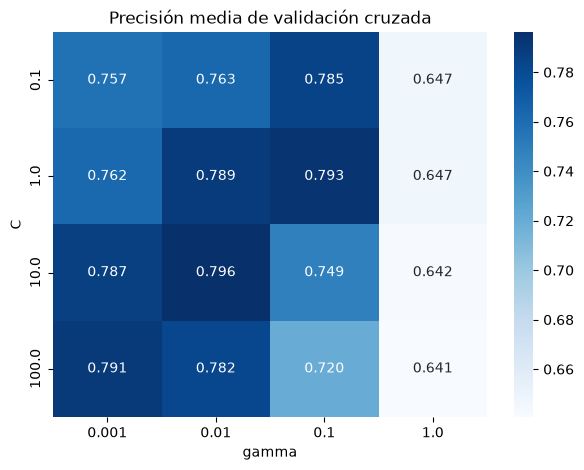

Combinación elegida: {'modelo__C': 10, 'modelo__gamma': 0.01}
Precisión media de validación cruzada: 0.796 | error típico: 0.012


In [28]:
# Paso 1. Búsqueda de C y gamma para la SVC, con la precisión media.
svc = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", SVC(kernel="rbf")),
])

malla_svc = {
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": [0.001, 0.01, 0.1, 1],
}

busqueda_svc = GridSearchCV(
    estimator=svc,
    param_grid=malla_svc,
    scoring="average_precision",
    cv=cv5,
    n_jobs=N_NUCLEOS,
)
busqueda_svc.fit(X_train, alto_train)

# Paso 2. Mapa de calor de la precisión media de validación cruzada.
resultados_svc = pd.DataFrame(busqueda_svc.cv_results_)
resultados_svc["error_tipico"] = resultados_svc["std_test_score"] / np.sqrt(5)

mapa_svc = resultados_svc.pivot(index="param_modelo__C",
                                columns="param_modelo__gamma",
                                values="mean_test_score")

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(mapa_svc, annot=True, fmt=".3f", cmap="Blues", ax=ax)
ax.set(xlabel="gamma", ylabel="C", title="Precisión media de validación cruzada")
plt.show()

# Paso 3. Combinación elegida y modelo elegido.
print("Combinación elegida:", busqueda_svc.best_params_)
fila_elegida_svc = resultados_svc.loc[busqueda_svc.best_index_]
print("Precisión media de validación cruzada:", round(fila_elegida_svc["mean_test_score"], 3),
      "| error típico:", round(fila_elegida_svc["error_tipico"], 3))

svc = busqueda_svc.best_estimator_

Paso 4. ¿Qué combinación eliges? ¿Qué pasa en la columna de `gamma=1`? ¿Se distingue la combinación elegida de sus vecinas en el mapa?

**Solución.**

- La búsqueda elige $C$ = 10 y $\gamma$ = 0,01, con una precisión media de validación cruzada de 0,796 y un error típico de 0,012.
- En la columna de $\gamma$ = 1, la precisión media cae a 0,64 con cualquier $C$. Pasa lo mismo que en la SVR: con ese $\gamma$, cada vector de soporte solo influye en trabajadores casi idénticos a él.
- Varias casillas quedan a menos de un error típico de la elegida: $C$ = 1 con $\gamma$ = 0,1 (0,793), $C$ = 100 con $\gamma$ = 0,001 (0,791) y $C$ = 1 con $\gamma$ = 0,01 (0,789). La validación cruzada no las distingue.
- Las mejores casillas forman una diagonal: un $\gamma$ menor pide un $C$ mayor. Es la misma relación entre los dos hiperparámetros que en el mapa de la SVR.

### Para pensar 4

En el mapa de calor de 4.1, ¿qué `C` da el menor RMSE en la columna del `gamma` más pequeño? ¿Y en la columna de `gamma=0.1`? ¿Se podría elegir `C` primero y `gamma` después?

<details><summary>Respuesta</summary>

- En la columna de $\gamma$ = 0,001, el RMSE baja al subir $C$, de 15 066 a 11 685 euros, y el mejor valor es $C$ = 100.
- En la columna de $\gamma$ = 0,1, el mejor valor es $C$ = 1 (11 213 euros). A partir de ahí el RMSE sube, hasta 12 985 euros con $C$ = 100.
- El mejor $C$ cambia con $\gamma$, así que no se pueden elegir uno detrás de otro.
- Con un $\gamma$ pequeño la función es muy suave, y hace falta un $C$ grande para que se acerque a los datos. Con un $\gamma$ grande la función ya es flexible, y un $C$ grande la lleva a reproducir el entrenamiento.
- Por eso los dos se buscan a la vez, con todas las combinaciones de la malla.

</details>

# Bloque 5. Comparación de modelos

## 5.1 Modelos de referencia en regresión

Comparamos la SVR elegida con tres modelos conocidos: la regresión lineal, el *random forest* y XGBoost.

- Los tres modelos de referencia usan los valores por defecto de sus hiperparámetros. Es una simplificación para que el cuaderno se ejecute en poco tiempo: lo riguroso es buscar también sus hiperparámetros, y con esa búsqueda su error puede bajar.
- Todos usan el mismo preprocesador. Los árboles no necesitan los predictores estandarizados, y tampoco les perjudica.
- Para cada modelo calculamos el RMSE de validación cruzada, su error típico y el tiempo de ajuste.
- `cross_validate` hace la validación cruzada como `cross_val_score` y devuelve un diccionario: `test_score` guarda las cinco puntuaciones y `fit_time`, los segundos de cada uno de los cinco ajustes.

Empezamos con la regresión lineal.

In [29]:
# Regresión lineal con el mismo preprocesador.
lineal = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", LinearRegression()),
])

cv_lineal = cross_validate(lineal, X_train, y_train, scoring="neg_root_mean_squared_error",
                           cv=cv5, n_jobs=N_NUCLEOS)

print("RMSE de validación cruzada:", round(-cv_lineal["test_score"].mean()), "euros")
print("Error típico:", round(cv_lineal["test_score"].std() / np.sqrt(5)))
print("Segundos por ajuste:", round(cv_lineal["fit_time"].mean(), 2))

RMSE de validación cruzada: 11956 euros
Error típico: 222
Segundos por ajuste: 0.05


Repetimos la celda para el *random forest*, XGBoost y la SVR elegida en 4.1.

In [30]:
# Random forest con sus valores por defecto (100 árboles sin límite de profundidad).
bosque = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", RandomForestRegressor(random_state=SEMILLA)),
])
cv_bosque = cross_validate(bosque, X_train, y_train, scoring="neg_root_mean_squared_error",
                           cv=cv5, n_jobs=N_NUCLEOS)

# XGBoost con sus valores por defecto.
xgb = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", XGBRegressor(random_state=SEMILLA)),
])
cv_xgb = cross_validate(xgb, X_train, y_train, scoring="neg_root_mean_squared_error",
                        cv=cv5, n_jobs=N_NUCLEOS)

# SVR con el C y el gamma elegidos en 4.1.
cv_svr = cross_validate(svr, X_train, y_train, scoring="neg_root_mean_squared_error",
                        cv=cv5, n_jobs=N_NUCLEOS)

In [31]:
# Reunimos los cuatro resultados en una tabla, con las mismas tres cifras de la regresión lineal.
resultados_regresion = {
    "Regresión lineal": cv_lineal,
    "Random forest": cv_bosque,
    "XGBoost": cv_xgb,
    "SVR con núcleo RBF": cv_svr,
}

filas = []
for nombre, resultado in resultados_regresion.items():
    filas.append({
        "modelo": nombre,
        "RMSE de validación cruzada (€)": -resultado["test_score"].mean(),
        "error típico (€)": resultado["test_score"].std() / np.sqrt(5),
        "segundos por ajuste": resultado["fit_time"].mean(),
    })

tabla_regresion = pd.DataFrame(filas)
tabla_regresion.round({"RMSE de validación cruzada (€)": 0, "error típico (€)": 0,
                       "segundos por ajuste": 2})

,modelo,RMSE de validación cruzada (€),error típico (€),segundos por ajuste
0,Regresión lineal,11956.0,222.0,0.05
1,Random forest,11475.0,215.0,3.60
2,XGBoost,11459.0,213.0,0.16
3,SVR con núcleo RBF,11213.0,181.0,2.38


**Lectura de los resultados.**

- La SVR con núcleo RBF tiene el menor RMSE de validación cruzada, 11 213 euros. La regresión lineal tiene el mayor, 11 956 euros.
- XGBoost (unos 11 450 euros) y el *random forest* (unos 11 500) quedan entre los dos.
- La SVR mejora a la regresión lineal en más de 700 euros, más de tres veces el error típico (unos 200 euros).
- Frente a XGBoost y al *random forest*, la ventaja de la SVR es de unos 250 euros, del orden de un error típico. La validación cruzada no la separa con claridad de ellos.
- La comparación favorece a la SVR, la única con hiperparámetros buscados.
- Los segundos por ajuste dependen del ordenador. La regresión lineal y XGBoost son los que menos tardan.
- El RMSE del *random forest* y el de XGBoost pueden cambiar unas decenas de euros de un ordenador a otro. En el *random forest* se debe a que sus árboles no tienen límite de profundidad.

---

## 5.2 Tiempo de ajuste y número de observaciones

El ajuste de una SVM con núcleo compara las observaciones por pares, y su coste crece más deprisa que el número de observaciones. Lo medimos ajustando la SVR elegida y el *random forest* con los primeros 1 000, 2 000, 4 000 y 8 000 trabajadores del entrenamiento.

- `time.perf_counter()` devuelve un instante en segundos. La diferencia entre dos llamadas es el tiempo transcurrido.
- `clone` crea una copia sin ajustar de un modelo, y así el ajuste con menos datos no cambia el modelo `svr`.

Primero, un ajuste con 1 000 trabajadores.

In [32]:
# Copia sin ajustar de la SVR elegida.
copia_svr = clone(svr)

# Segundos que tarda un ajuste con los primeros 1 000 trabajadores.
inicio = time.perf_counter()
copia_svr.fit(X_train.iloc[:1000], y_train.iloc[:1000])
segundos = time.perf_counter() - inicio
print("SVR con 1 000 trabajadores:", round(segundos, 2), "segundos")

SVR con 1 000 trabajadores: 0.06 segundos


Repetimos las operaciones del ejemplo anterior con los cuatro tamaños y los dos modelos.

SVR, de 1 000 a 8 000 observaciones: tarda 49 veces más
Random forest, de 1 000 a 8 000 observaciones: tarda 8 veces más


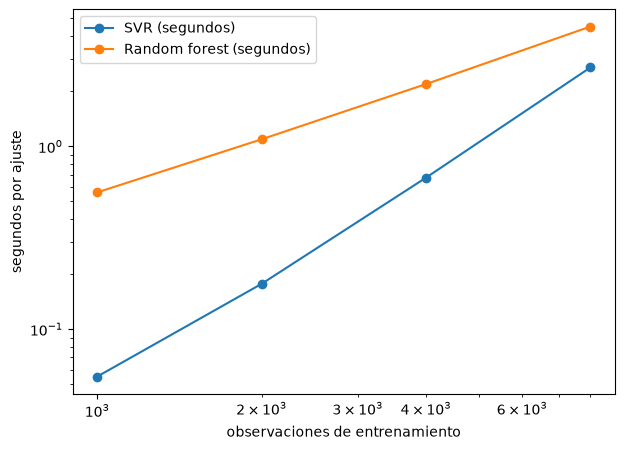

In [33]:
tamanos = [1000, 2000, 4000, 8000]
segundos_svr = []
segundos_bosque = []

for n in tamanos:
    # SVR elegida.
    copia_svr = clone(svr)
    inicio = time.perf_counter()
    copia_svr.fit(X_train.iloc[:n], y_train.iloc[:n])
    segundos_svr.append(time.perf_counter() - inicio)

    # Random forest.
    copia_bosque = clone(bosque)
    inicio = time.perf_counter()
    copia_bosque.fit(X_train.iloc[:n], y_train.iloc[:n])
    segundos_bosque.append(time.perf_counter() - inicio)

tabla_tiempos = pd.DataFrame({
    "observaciones": tamanos,
    "SVR (segundos)": segundos_svr,
    "Random forest (segundos)": segundos_bosque,
})

# Cuántas veces más tarda cada modelo con 8 000 observaciones que con 1 000.
print("SVR, de 1 000 a 8 000 observaciones: tarda",
      round(segundos_svr[3] / segundos_svr[0]), "veces más")
print("Random forest, de 1 000 a 8 000 observaciones: tarda",
      round(segundos_bosque[3] / segundos_bosque[0]), "veces más")

# Los dos ejes en escala logarítmica: una recta con más pendiente crece más deprisa.
ax = tabla_tiempos.plot(x="observaciones", marker="o", logx=True, logy=True, figsize=(7, 5))
ax.set(xlabel="observaciones de entrenamiento", ylabel="segundos por ajuste")
plt.show()

**Lectura de los resultados.**

- Los segundos cambian con el ordenador. Lo que se compara es cuánto crece el tiempo de cada modelo al pasar de 1 000 a 8 000 observaciones, 8 veces más.
- Si el tiempo creciera en proporción al número de observaciones, el ajuste tardaría 8 veces más. Si creciera con su cuadrado, 64 veces más.
- El tiempo del *random forest* crece cerca de esas 8 veces. El de la SVR crece mucho más, y en la figura su línea tiene más pendiente.
- Con estos tamaños la SVR todavía se ajusta en poco tiempo. Si su línea mantiene esa pendiente, con cientos de miles de observaciones el ajuste deja de ser práctico.

---

## 5.3 Evaluación final en el test

La elección de los modelos se ha hecho con validación cruzada en el entrenamiento. El test se usa una sola vez, al final, para informar del error de cada modelo con datos que ninguno ha visto, y no cambia la elección.

Ajustamos cada modelo con todo el entrenamiento y calculamos su RMSE en el test. Primero, la regresión lineal.

In [34]:
# Ajuste con todo el entrenamiento y RMSE en el test.
lineal.fit(X_train, y_train)
prediccion_test = lineal.predict(X_test)
rmse_lineal_test = root_mean_squared_error(y_test, prediccion_test)
print("Regresión lineal | RMSE en el test:", round(rmse_lineal_test), "euros")

Regresión lineal | RMSE en el test: 11860 euros


Repetimos las operaciones del ejemplo anterior con los cuatro modelos y añadimos la columna a la tabla de 5.1.

In [35]:
# Los cuatro modelos de la tabla de 5.1.
modelos_regresion = {
    "Regresión lineal": lineal,
    "Random forest": bosque,
    "XGBoost": xgb,
    "SVR con núcleo RBF": svr,
}

rmse_test = []
for nombre, modelo in modelos_regresion.items():
    # Ajuste con todo el entrenamiento y RMSE en el test.
    modelo.fit(X_train, y_train)
    prediccion_test = modelo.predict(X_test)
    rmse_test.append(root_mean_squared_error(y_test, prediccion_test))

tabla_regresion["RMSE en el test (€)"] = rmse_test
tabla_regresion.round({"RMSE de validación cruzada (€)": 0, "error típico (€)": 0,
                       "segundos por ajuste": 2, "RMSE en el test (€)": 0})

,modelo,RMSE de validación cruzada (€),error típico (€),segundos por ajuste,RMSE en el test (€)
0,Regresión lineal,11956.0,222.0,0.05,11860.0
1,Random forest,11475.0,215.0,3.60,11124.0
2,XGBoost,11459.0,213.0,0.16,10883.0
3,SVR con núcleo RBF,11213.0,181.0,2.38,10602.0


**Lectura de los resultados.**

- En el test, la SVR tiene un RMSE de 10 602 euros, XGBoost de unos 10 900, el *random forest* de unos 11 100 y la regresión lineal de 11 860.
- El orden de los modelos es el mismo que con la validación cruzada.
- El test tiene 2 000 trabajadores, y sus cifras también tienen error de muestreo. Informan del error de cada modelo y no sirven para volver a elegir.

---

### Ejercicio 5. Comparación en clasificación

Construye la tabla de comparación para el salario alto (`alto_train`).

1. Define tres modelos de referencia con `preprocesar` y sus valores por defecto: `LogisticRegression(max_iter=2000)`, `RandomForestClassifier(random_state=SEMILLA)` y `XGBClassifier(random_state=SEMILLA)`. Define también una SVC con el `C` y el `gamma` que elegiste en el ejercicio 4 y `class_weight="balanced"`, que multiplica el coste de las pérdidas de la clase menos frecuente.
2. Calcula para los cinco modelos (los tres de referencia, tu `svc` del ejercicio 4 y la SVC con `class_weight="balanced"`) la precisión media y el F1 de validación cruzada. `cross_validate` admite una lista en `scoring`: con `scoring=["average_precision", "f1"]` devuelve `test_average_precision` y `test_f1`. El F1 es la media armónica de la precisión y la sensibilidad, y se calcula con la clase que predice el modelo.
3. Reúne en una tabla la precisión media, su error típico, el F1 y los segundos por ajuste de cada modelo.
4. ¿Qué modelo elegirías para predecir el salario alto? Ten en cuenta el error típico y el tiempo de ajuste. ¿Qué cambia `class_weight="balanced"` y por qué cambia el F1 más que la precisión media?

In [36]:
# Paso 1. Modelos de referencia y SVC con class_weight="balanced".
logit = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", LogisticRegression(max_iter=2000)),
])
bosque_c = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", RandomForestClassifier(random_state=SEMILLA)),
])
xgb_c = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", XGBClassifier(random_state=SEMILLA)),
])
svc_equilibrada = Pipeline([
    ("preprocesado", preprocesar),
    ("modelo", SVC(kernel="rbf",
                   C=busqueda_svc.best_params_["modelo__C"],
                   gamma=busqueda_svc.best_params_["modelo__gamma"],
                   class_weight="balanced")),
])

# Paso 2. Precisión media y F1 de validación cruzada de los cinco modelos.
modelos_clasificacion = {
    "Logit": logit,
    "Random forest": bosque_c,
    "XGBoost": xgb_c,
    "SVC con núcleo RBF": svc,
    "SVC con class_weight='balanced'": svc_equilibrada,
}

filas = []
for nombre, modelo in modelos_clasificacion.items():
    resultado = cross_validate(modelo, X_train, alto_train, scoring=["average_precision", "f1"],
                               cv=cv5, n_jobs=N_NUCLEOS)
    # Paso 3. Una fila por modelo.
    filas.append({
        "modelo": nombre,
        "precisión media de validación cruzada": resultado["test_average_precision"].mean(),
        "error típico": resultado["test_average_precision"].std() / np.sqrt(5),
        "F1 de validación cruzada": resultado["test_f1"].mean(),
        "segundos por ajuste": resultado["fit_time"].mean(),
    })

tabla_clasificacion = pd.DataFrame(filas)
tabla_clasificacion.round(3)

,modelo,precisión media de validación cruzada,error típico,F1 de validación cruzada,segundos por ajuste
0,Logit,0.790,0.012,0.701,0.059
1,Random forest,0.789,0.013,0.692,0.505
2,XGBoost,0.794,0.010,0.708,0.155
3,SVC con núcleo RBF,0.796,0.012,0.711,1.103
4,SVC con class_weight='balanced',0.793,0.013,0.720,1.348


Paso 4. ¿Qué modelo elegirías para predecir el salario alto? ¿Qué cambia `class_weight="balanced"` y por qué cambia el F1 más que la precisión media?

**Solución.**

- La tabla, con las cifras de la ejecución de estas soluciones:

| Modelo | Precisión media | Error típico | F1 |
|---|---|---|---|
| Logit | 0,790 | 0,012 | 0,701 |
| *Random forest* | unos 0,79 | 0,013 | unos 0,69 |
| XGBoost | 0,794 | 0,010 | 0,708 |
| SVC con núcleo RBF | 0,796 | 0,012 | 0,711 |
| SVC con `class_weight="balanced"` | 0,793 | 0,013 | 0,720 |

- **Elección.** Las precisiones medias van de 0,789 a 0,796, y la diferencia entre la mayor y la menor es algo más de la mitad de un error típico. La validación cruzada no distingue los cinco modelos.
- Con un error parecido, deciden el coste y lo fácil que es explicar el modelo. El logit se ajusta en centésimas de segundo, da probabilidades y sus coeficientes se interpretan. Es una elección sólida.
- La SVC tarda más en ajustarse, hay que buscar sus dos hiperparámetros y no da probabilidades. Aquí no compensa.
- **`class_weight="balanced"`.** Multiplica el coste de las pérdidas de los positivos, la clase menos frecuente. La frontera se desplaza y el modelo predice más positivos: gana sensibilidad y pierde precisión. El F1 sube de 0,711 a 0,720.
- La precisión media casi no cambia (0,796 y 0,793), porque mide cómo ordena el modelo a los trabajadores con su puntuación, y los pesos apenas cambian ese orden.
- El F1 se calcula con la clase predicha, que depende de dónde se corta la puntuación. Por eso un cambio en el corte lo mueve más que a la precisión media.

### Para pensar 5

La encuesta completa tiene unos 240 000 trabajadores, y aquí hemos usado 8 000 para entrenar. ¿Qué alternativas hay para usar una SVM con todos los datos?

<details><summary>Respuesta</summary>

- Con la SVM con núcleo de `SVC` y `SVR`, el coste del ajuste crece entre el cuadrado y el cubo del número de observaciones. Con cientos de miles deja de ser práctico, y una búsqueda de hiperparámetros multiplica ese coste por el número de ajustes.
- Primera alternativa: ajustar la SVM con núcleo sobre una submuestra, como hemos hecho aquí.
- Segunda: una SVM lineal con `LinearSVC` o `LinearSVR`, implementaciones pensadas para muchas observaciones. Se pierde la frontera curva del núcleo.
- Tercera: aproximar el núcleo con unos cientos de columnas nuevas (`Nystroem`, de scikit-learn) y ajustar con ellas un modelo lineal.
- También cabe elegir otro modelo. Los ensambles de árboles se ajustan con cientos de miles de observaciones sin dificultad, y en estos datos su error es parecido.

</details>

# Tarea opcional. Núcleo polinómico

El núcleo RBF no es el único. El **núcleo polinómico** (`kernel="poly"`) equivale a añadir las potencias de los predictores y sus productos hasta el grado que fija `degree`, sin construir esas columnas.

### Ejercicio 6. Frontera con núcleo polinómico

1. Con los 300 trabajadores de 2.1 (`X_300` y `alto_300`), ajusta una SVC con `kernel="poly"`, `C=1` y `degree` igual a 2 y a 3. Dibuja las dos fronteras con `dibujar_frontera`.
2. Con todo el entrenamiento y los dos predictores (`X_dos` y `alto_train`), calcula la precisión media de validación cruzada de las dos SVC polinómicas y de la SVC con núcleo RBF y `gamma=1`.
3. ¿En qué se diferencian las fronteras de la del núcleo RBF de 2.2? ¿Qué núcleo elegirías con estos dos predictores?

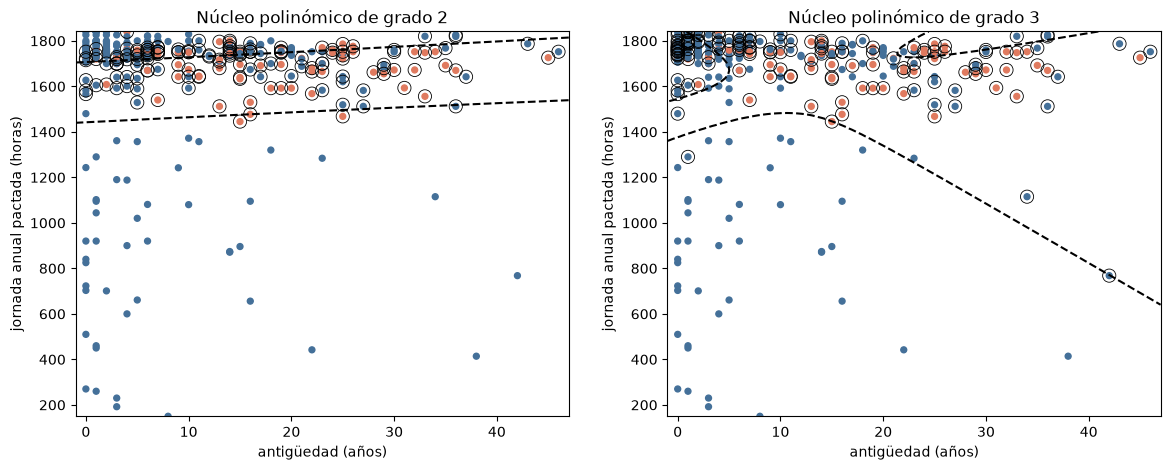

In [37]:
# Paso 1. SVC con núcleo polinómico de grado 2 y de grado 3.
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))

grado_grid = [2, 3]
for ax, grado in zip(ejes, grado_grid):
    modelo = Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", SVC(kernel="poly", C=1, degree=grado)),
    ])
    modelo.fit(X_300, alto_300)
    dibujar_frontera(modelo, X_300, alto_300, ax, f"Núcleo polinómico de grado {grado}")
plt.show()

In [ ]:
# Comprobación: f(x) de las dos SVC polinómicas con la tolerancia por defecto del ajuste
# (tol=0.001) y con una más estricta (tol=1e-6).
filas_poli = []
for grado in grado_grid:
    for tol in [1e-3, 1e-6]:
        modelo = Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", SVC(kernel="poly", C=1, degree=grado, tol=tol)),
        ])
        f_poli = modelo.fit(X_300, alto_300).decision_function(X_300)
        filas_poli.append({"grado": grado, "tol": tol,
                           "f(x) mínima": f_poli.min(), "f(x) máxima": f_poli.max()})
pd.DataFrame(filas_poli).round({"f(x) mínima": 3, "f(x) máxima": 3})

,grado,tol,f(x) mínima,f(x) máxima
0,2,0.001000,-1.052,-1.000
1,2,0.000001,-1.000,-1.000
2,3,0.001000,-1.117,-0.996
3,3,0.000001,-1.000,-1.000


In [38]:
# Paso 2. Precisión media de validación cruzada de los tres núcleos, con todo el entrenamiento.
nucleos = {
    "Polinómico de grado 2": SVC(kernel="poly", C=1, degree=2),
    "Polinómico de grado 3": SVC(kernel="poly", C=1, degree=3),
    "RBF con gamma = 1": SVC(kernel="rbf", C=1, gamma=1),
}

for nombre, nucleo in nucleos.items():
    modelo = Pipeline([
        ("escalado", StandardScaler()),
        ("modelo", nucleo),
    ])
    puntuaciones = cross_val_score(modelo, X_dos, alto_train, scoring="average_precision",
                                   cv=cv5, n_jobs=N_NUCLEOS)
    print(nombre, "| precisión media de validación cruzada:", round(puntuaciones.mean(), 3),
          "| error típico:", round(puntuaciones.std() / np.sqrt(5), 3))

Polinómico de grado 2 | precisión media de validación cruzada: 0.354 | error típico: 0.013


Polinómico de grado 3 | precisión media de validación cruzada: 0.442 | error típico: 0.016


RBF con gamma = 1 | precisión media de validación cruzada: 0.468 | error típico: 0.017


In [ ]:
# Comprobación: f(x) del polinomio de grado 2 ajustado con todo el entrenamiento.
grado_2 = Pipeline([
    ("escalado", StandardScaler()),
    ("modelo", SVC(kernel="poly", C=1, degree=2)),
])
f_grado_2 = grado_2.fit(X_dos, alto_train).decision_function(X_dos)
print("Grado 2 con todo el entrenamiento | f(x) mínima:", f_grado_2.min().round(3),
      "| f(x) máxima:", f_grado_2.max().round(3))

Grado 2 con todo el entrenamiento | f(x) mínima: -1.013 | f(x) máxima: -0.991


Paso 3. ¿En qué se diferencian las fronteras de la del núcleo RBF de 2.2? ¿Qué núcleo elegirías con estos dos predictores?

**Solución.**

- En los dos paneles falta la línea continua. Con estos 300 trabajadores, ninguna de las dos SVC polinómicas predice un positivo.
- **Aviso.** Las líneas discontinuas no son bordes del margen. Con la tolerancia por defecto, $f(x)$ va de −1,052 a −1,000 con grado 2 y de −1,117 a −0,996 con grado 3. Con `tol=1e-6`, el ajuste se detiene más cerca de la solución, y $f(x)$ vale −1 en los 300 trabajadores con los dos grados. Pasa lo mismo que con la SVC lineal de 2.2: no hay frontera ni bordes del margen, y las líneas son restos del ajuste.
- La frontera del núcleo RBF de 2.2 es una curva cerrada alrededor de la zona con más positivos. Con estos 300 trabajadores, `C=1` y sin pesos, los dos polinomios no encuentran ninguna frontera.
- La precisión media de validación cruzada es de 0,354 con grado 2, 0,442 con grado 3 y 0,468 con el núcleo RBF.
- **Aviso.** Con todo el entrenamiento, el polinomio de grado 2 también da una puntuación casi constante, de −1,013 a −0,991. Su precisión media ordena a los trabajadores por los restos del ajuste, y no se puede comparar con las otras dos.
- La diferencia entre el núcleo RBF y el polinómico de grado 3 es de 0,026, más que el error típico de cualquiera de los dos (0,016 y 0,017). Con estos dos predictores elegimos el núcleo RBF.